<a href="https://colab.research.google.com/github/vongocgiavy/linh/blob/main/Mat_bang_kho.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Tai file Excel mau mau_du_lieu_kho_ABC.xlsx len.


Saving mau_du_lieu_kho_ABC.xlsx to mau_du_lieu_kho_ABC (5).xlsx

===== TONG HOP PHAN LOAI ABC =====
     So_SKU  Tong_luot_lay_ngay
ABC                            
A        21                 638
B        16                 121
C         9                  35


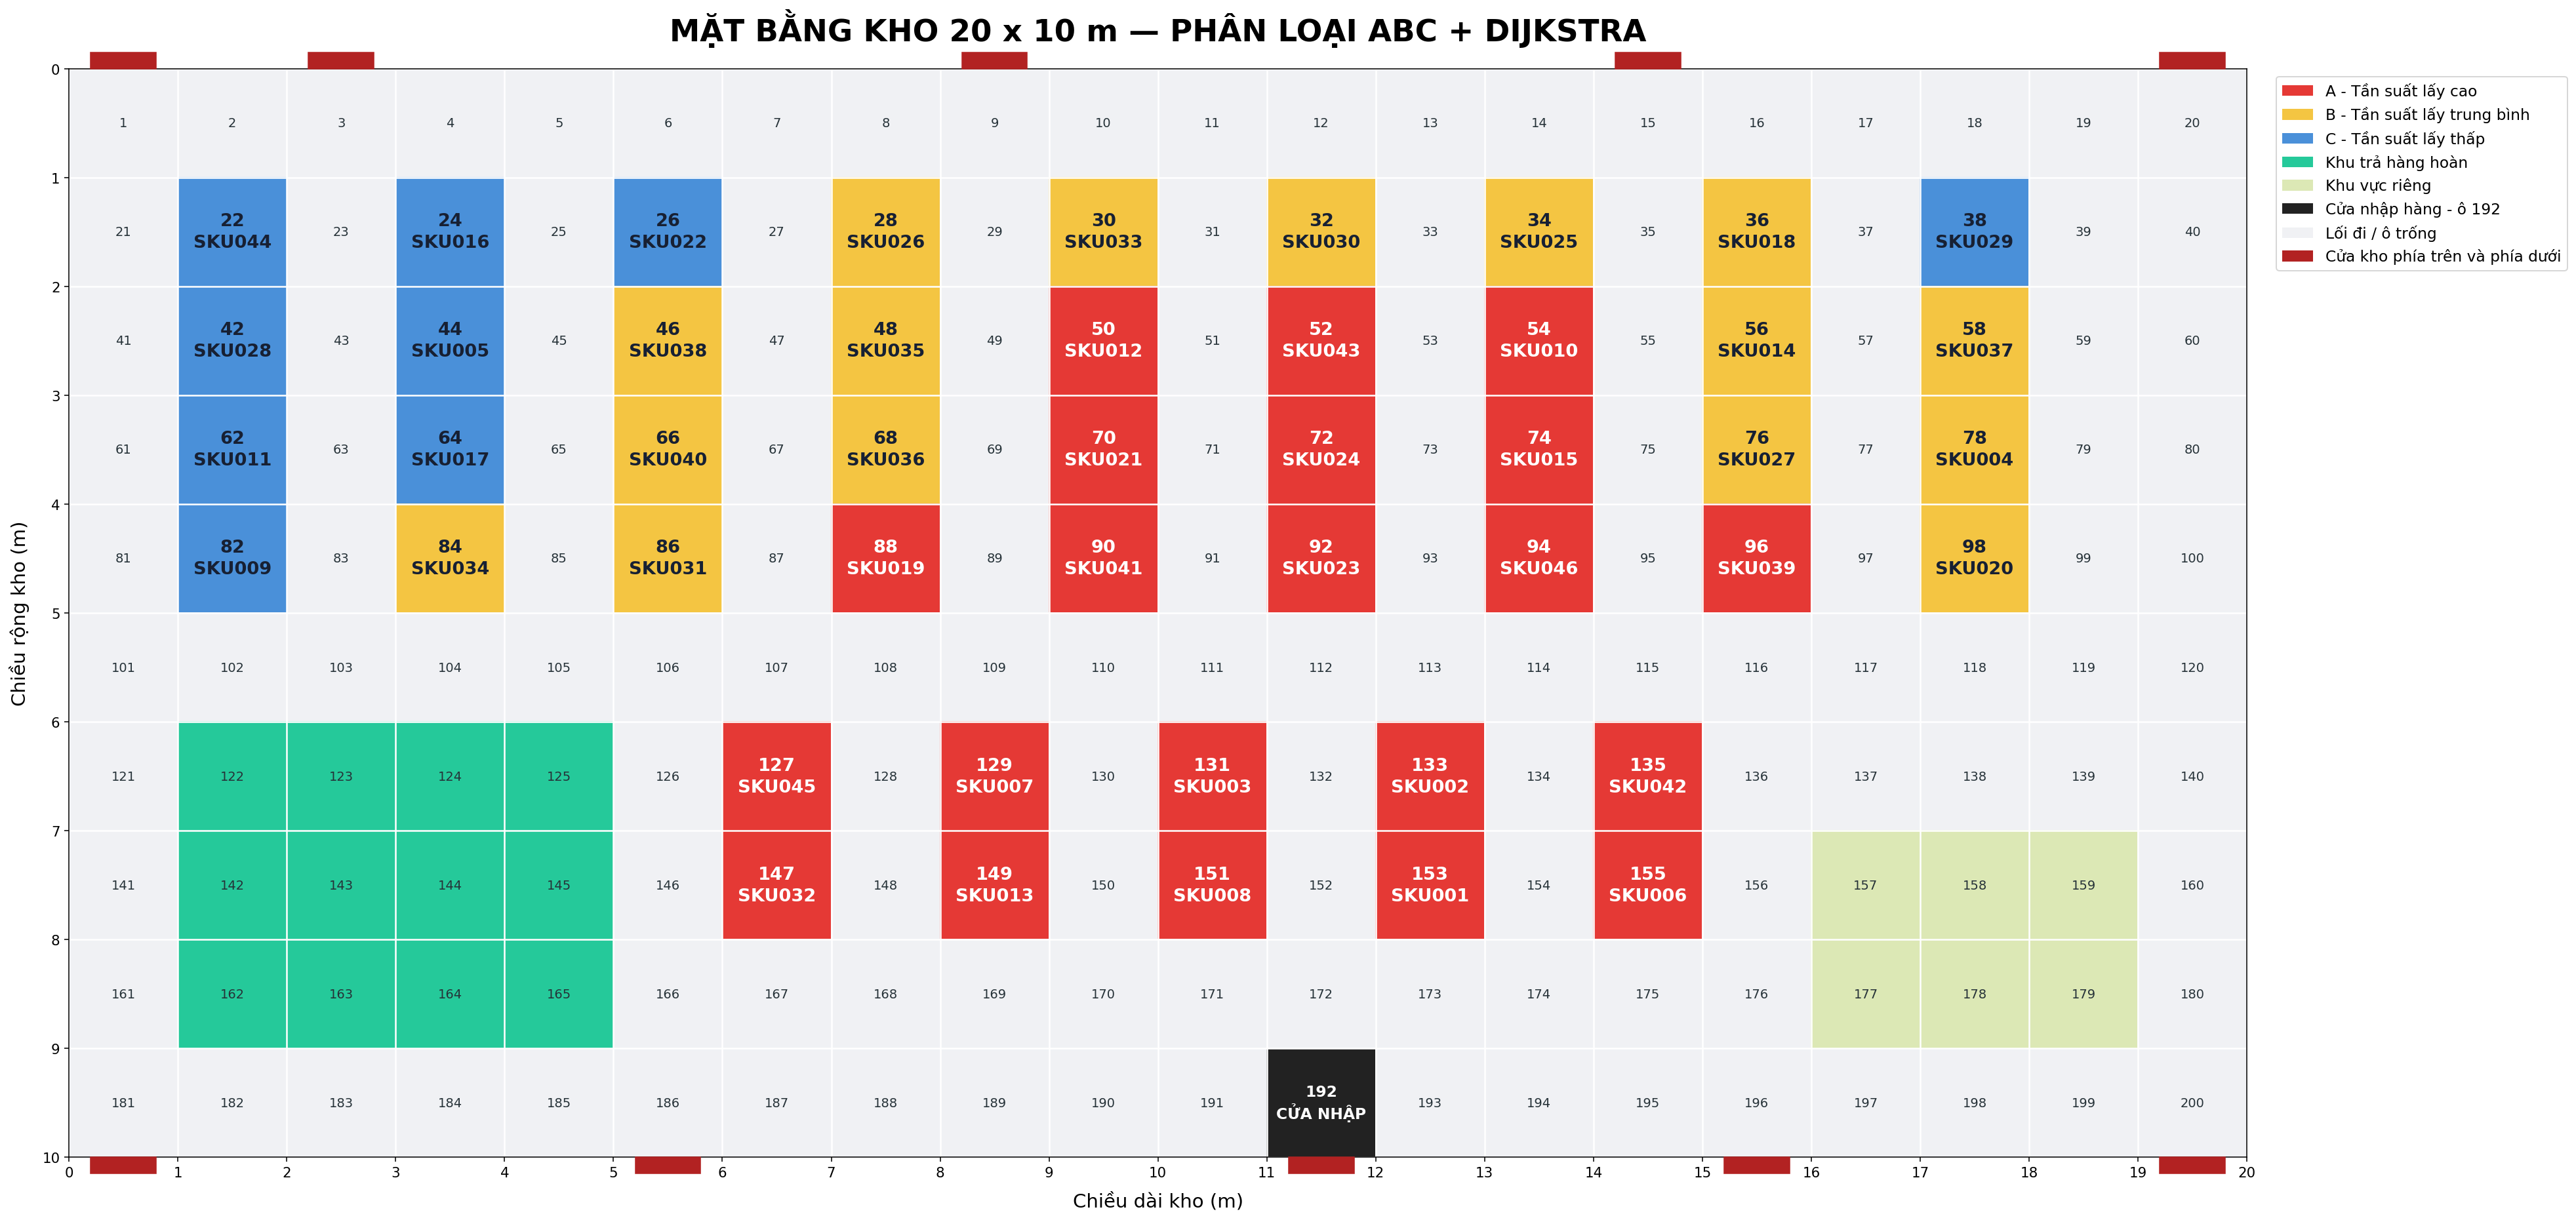


===== KET QUA A* TU O 157 DEN O 42 =====
O bat dau: 157
O dich: 42
Thuat toan: A* (heuristic Manhattan)
Thoi gian xu ly: 0.2147 ms (0.00021468 giay)
So nut da xet: 45
So buoc di ngan nhat: 20
Tong so o tren lo trinh: 21
Lo trinh: 157 -> 137 -> 117 -> 116 -> 115 -> 114 -> 113 -> 112 -> 111 -> 110 -> 109 -> 108 -> 107 -> 106 -> 105 -> 104 -> 103 -> 83 -> 63 -> 43 -> 42


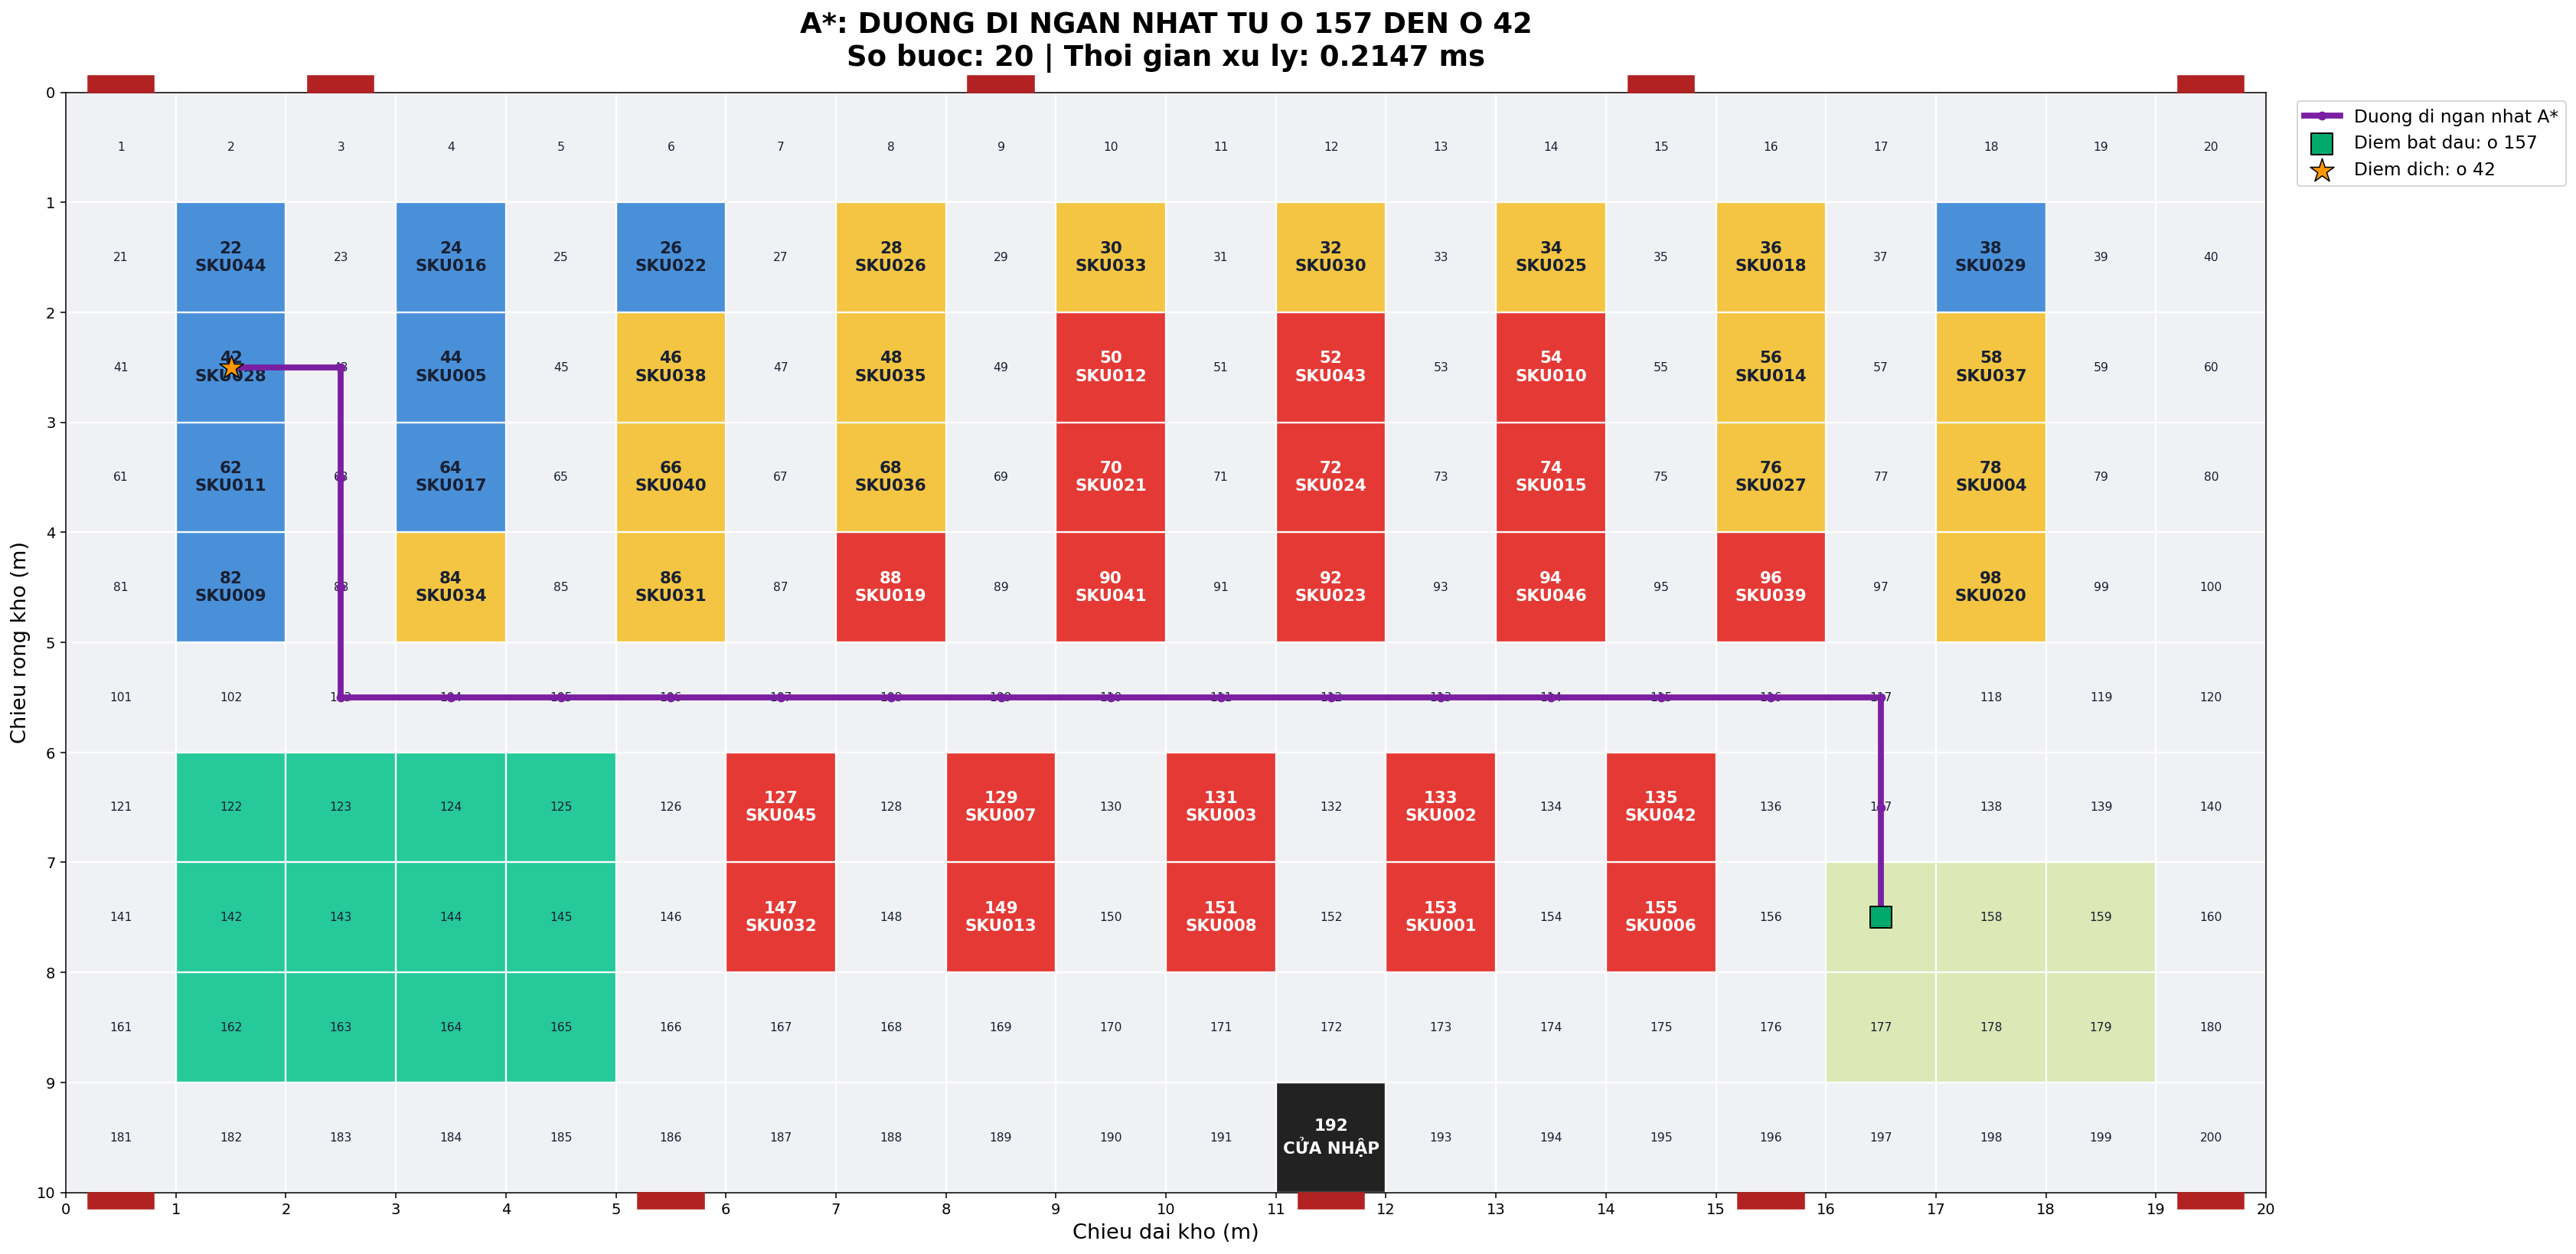


===== THONG KE ABC VA KHOANG CACH =====
     So_SKU  Tong_luot_lay_ngay  Khoang_cach_trung_binh
ABC                                                    
A        21                 638                    6.62
B        16                 121                   11.31
C         9                  35                   15.44


In [11]:
# ============================================================
# SMART LOGISTICS: MO HINH KHO 20 x 10 m
# ABC SLOTting + A* ROUTING + HIEN THI SKU CHU LON
# Chay tren Google Colab
# ============================================================

import heapq
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from google.colab import files

# ============================================================
# 1. THONG SO KHO
# ============================================================
ROWS, COLS = 10, 20
TOTAL_CELLS = ROWS * COLS
DOOR = 192  # Cua nhap hang

# Cac cua kho mau do nam tren duong vien ngoai, tham khao notebook mau.
# Vi tri cot dung chi so 0-19, doc tu trai sang phai.
TOP_DOORS = [0, 2, 8, 14, 19]
BOTTOM_DOORS = [0, 5, 11, 15, 19]
DOOR_COLOR = "#b22222"

ids = np.arange(1, TOTAL_CELLS + 1).reshape(ROWS, COLS)

def pos(cell):
    """Doi ma o 1-200 thanh toa do (hang, cot), bat dau tu tren xuong."""
    return (int(cell) - 1) // COLS, (int(cell) - 1) % COLS

def cell_id(r, c):
    """Doi toa do (hang, cot) thanh ma o 1-200."""
    return r * COLS + c + 1

def neighbors(cell):
    """Cac o ke can theo 4 huong: tren, duoi, trai, phai."""
    r, c = pos(cell)
    result = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nr, nc = r + dr, c + dc
        if 0 <= nr < ROWS and 0 <= nc < COLS:
            result.append(cell_id(nr, nc))
    return result

# ============================================================
# 2. KHAI BAO KE VA CAC KHU VUC CO DINH
# ============================================================
# Cac day ke doc theo so do da thong nhat.
shelf_starts = [22, 24, 26, 28, 30, 32, 34, 36, 38]
rack_cells = []
for start in shelf_starts:
    rack_cells.extend([start, start + 20, start + 40, start + 60])

# Cac vi tri xanh duong: chi lay 2 o phia tren moi cot.
blue_cells = [
    127, 147,
    129, 149,
    131, 151,
    133, 153,
    135, 155
]
rack_cells = list(dict.fromkeys(rack_cells + blue_cells))

# Khu tra hang hoan 4 cot x 3 hang.
return_cells = (
    list(range(122, 126))
    + list(range(142, 146))
    + list(range(162, 166))
)

# Khu vuc rieng ben phai theo so do.
other_cells = (
    list(range(157, 160))
    + list(range(177, 180))
)

fixed_cells = set(return_cells + other_cells)
rack_cells = [cell for cell in rack_cells if cell not in fixed_cells]

# Cua nhap tai o 192 khong duoc xem la vat can.
fixed_cells.discard(DOOR)

# ============================================================
# 3. DOC DU LIEU SKU TU FILE EXCEL
# ============================================================
print("Tai file Excel mau mau_du_lieu_kho_ABC.xlsx len.")
uploaded = files.upload()
if not uploaded:
    raise ValueError("Ban chua tai file Excel len.")

filename = next(iter(uploaded))
df = pd.read_excel(filename, sheet_name="SKU_TanSuat")

required_columns = ["SKU", "Số lần lấy/ngày"]
missing = [col for col in required_columns if col not in df.columns]
if missing:
    raise ValueError(f"File Excel thieu cot bat buoc: {missing}")

df["Số lần lấy/ngày"] = pd.to_numeric(
    df["Số lần lấy/ngày"], errors="coerce"
).fillna(0)

if df.empty:
    raise ValueError("Danh sach SKU trong Excel dang rong.")

# ============================================================
# 4. PHAN LOAI ABC THEO TAN SUAT LAY HANG
# ============================================================
df = df.sort_values(
    "Số lần lấy/ngày", ascending=False
).reset_index(drop=True)

total_picks = df["Số lần lấy/ngày"].sum()

if total_picks > 0:
    df["Tỷ trọng"] = df["Số lần lấy/ngày"] / total_picks
    df["Tỷ trọng tích lũy"] = df["Tỷ trọng"].cumsum()
else:
    df["Tỷ trọng"] = 0.0
    df["Tỷ trọng tích lũy"] = 0.0

# SKU bat dau o nguong nao thi duoc xep vao nhom nguong do.
previous_cumulative = df["Tỷ trọng tích lũy"] - df["Tỷ trọng"]
df["ABC"] = np.select(
    [
        previous_cumulative < 0.80,
        previous_cumulative < 0.95
    ],
    ["A", "B"],
    default="C"
)

print("\n===== TONG HOP PHAN LOAI ABC =====")
print(
    df.groupby("ABC").agg(
        So_SKU=("SKU", "count"),
        Tong_luot_lay_ngay=("Số lần lấy/ngày", "sum")
    )
)

# ============================================================
# 5. XAY DUNG LUOI DI CHUYEN CHO ROBOT
# ============================================================
# O ke va khu vuc co dinh la vat can.
# Cac o con lai la duong di.
blocked = set(rack_cells) | fixed_cells
blocked.discard(DOOR)

walkable = {
    cell for cell in range(1, TOTAL_CELLS + 1)
    if cell not in blocked
}

if DOOR not in walkable:
    raise ValueError("O cua nhap 192 khong nam tren luoi di chuyen.")

# ============================================================
# 6. DIJKSTRA: TIM KHOANG CACH NGAN NHAT TU CUA NHAP
# ============================================================
def dijkstra(start, walkable_cells):
    distances = {cell: float("inf") for cell in walkable_cells}
    previous = {}
    distances[start] = 0
    heap = [(0, start)]

    while heap:
        distance, current = heapq.heappop(heap)

        if distance > distances[current]:
            continue

        for nxt in neighbors(current):
            if nxt not in walkable_cells:
                continue

            new_distance = distance + 1
            if new_distance < distances[nxt]:
                distances[nxt] = new_distance
                previous[nxt] = current
                heapq.heappush(heap, (new_distance, nxt))

    return distances, previous

distances, previous = dijkstra(DOOR, walkable)

def get_access_cell(rack):
    """Tim o duong di gan ke nhat ma robot co the tiep can."""
    candidates = [
        cell for cell in neighbors(rack)
        if cell in walkable and distances.get(cell, float("inf")) < float("inf")
    ]
    if not candidates:
        return None
    return min(candidates, key=lambda cell: (distances[cell], cell))

rack_access = {}
for rack in rack_cells:
    access = get_access_cell(rack)
    if access is not None:
        rack_access[rack] = access

rack_distances = {
    rack: distances[access] + 1
    for rack, access in rack_access.items()
}

# ============================================================
# 7. GAN SKU TAN SUAT CAO VAO KE GAN CUA HON
# ============================================================
available_racks = sorted(
    rack_distances.keys(),
    key=lambda rack: (rack_distances[rack], rack)
)

if len(df) > len(available_racks):
    raise ValueError(
        f"Co {len(df)} SKU nhung chi co {len(available_racks)} "
        "vi tri ke tiep can duoc. Hay tang so vi tri ke hoac giam SKU."
    )

# SKU da duoc sap xep tu tan suat cao xuong thap.
# Vi tri ke cung duoc sap xep tu gan den xa.
df["Ô lưu trữ"] = available_racks[:len(df)]
df["Khoảng cách từ cửa (ô)"] = df["Ô lưu trữ"].map(rack_distances)
df["Ô tiếp cận robot"] = df["Ô lưu trữ"].map(rack_access)

# ============================================================
# 8. TAO BAN DO MAU ABC VA MA SKU
# ============================================================
# Ma khu vuc:
# 0 = loi di / o trong
# 1 = ke A
# 2 = ke B
# 3 = ke C
# 4 = khu tra hang hoan
# 5 = khu vuc rieng
# 6 = cua nhap hang

layout = np.zeros((ROWS, COLS), dtype=int)
sku_map = {}
abc_code = {"A": 1, "B": 2, "C": 3}

for _, row in df.iterrows():
    rack = int(row["Ô lưu trữ"])
    r, c = pos(rack)
    layout[r, c] = abc_code[row["ABC"]]
    sku_map[rack] = str(row["SKU"])

for cell in return_cells:
    r, c = pos(cell)
    layout[r, c] = 4

for cell in other_cells:
    r, c = pos(cell)
    layout[r, c] = 5

r_door, c_door = pos(DOOR)
layout[r_door, c_door] = 6

colors = [
    "#F0F1F4",  # 0: loi di
    "#E53935",  # 1: A
    "#F4C542",  # 2: B
    "#4A90D9",  # 3: C
    "#25C99A",  # 4: tra hang hoan
    "#DCE8B5",  # 5: khu vuc rieng
    "#222222"   # 6: cua nhap
]
cmap = ListedColormap(colors)

# ============================================================
# 9. VE MAT BANG KHO - CHU SKU TO, DAM, DE DOC
# ============================================================
fig, ax = plt.subplots(figsize=(28, 14), dpi=140)

ax.imshow(
    layout,
    cmap=cmap,
    vmin=0,
    vmax=6,
    origin="upper",
    extent=[0, COLS, ROWS, 0],
    interpolation="none",
    aspect="equal"
)

ax.set_xticks(np.arange(0, COLS + 1, 1))
ax.set_yticks(np.arange(0, ROWS + 1, 1))
ax.grid(color="white", linewidth=1.3)

# ============================================================
# 9A. VE CUA KHO MAU DO O VIEN TREN VA VIEN DUOI
# Tham khao Mat bang kho thay.ipynb: cua nam ngoai luoi kho.
# ============================================================
from matplotlib.patches import Rectangle

for c in TOP_DOORS:
    ax.add_patch(
        Rectangle(
            (c + 0.2, -0.15), 0.6, 0.15,
            facecolor=DOOR_COLOR, edgecolor=DOOR_COLOR,
            linewidth=0.8, zorder=10, clip_on=False
        )
    )

for c in BOTTOM_DOORS:
    ax.add_patch(
        Rectangle(
            (c + 0.2, ROWS), 0.6, 0.15,
            facecolor=DOOR_COLOR, edgecolor=DOOR_COLOR,
            linewidth=0.8, zorder=10, clip_on=False
        )
    )

for r in range(ROWS):
    for c in range(COLS):
        cell = int(ids[r, c])
        category = layout[r, c]

        if cell == DOOR:
            # Cua nhap: chu ro va dam
            ax.text(
                c + 0.5, r + 0.5,
                "192\nCỬA NHẬP",
                ha="center", va="center",
                fontsize=12, fontweight="bold",
                color="white", linespacing=1.2
            )
        elif cell in sku_map:
            # O co hang: ma o nho hon, ma SKU lon va dam
            ax.text(
                c + 0.5, r + 0.5,
                f"{cell}\n{sku_map[cell]}",
                ha="center", va="center",
                fontsize=14, fontweight="bold",
                color="white" if category == 1 else "#172033",
                linespacing=1.35
            )
        else:
            # O khong co SKU: chi hien ma o
            ax.text(
                c + 0.5, r + 0.5,
                str(cell),
                ha="center", va="center",
                fontsize=10, color="#263238"
            )

ax.set_xlim(0, COLS)
ax.set_ylim(ROWS, 0)
ax.set_xlabel("Chiều dài kho (m)", fontsize=15, labelpad=10)
ax.set_ylabel("Chiều rộng kho (m)", fontsize=15, labelpad=10)
ax.tick_params(axis="both", labelsize=11)

ax.set_title(
    "MẶT BẰNG KHO 20 x 10 m — PHÂN LOẠI ABC + DIJKSTRA",
    fontsize=24, fontweight="bold", pad=22
)

legend_items = [
    Patch(facecolor=colors[1], label="A - Tần suất lấy cao"),
    Patch(facecolor=colors[2], label="B - Tần suất lấy trung bình"),
    Patch(facecolor=colors[3], label="C - Tần suất lấy thấp"),
    Patch(facecolor=colors[4], label="Khu trả hàng hoàn"),
    Patch(facecolor=colors[5], label="Khu vực riêng"),
    Patch(facecolor=colors[6], label="Cửa nhập hàng - ô 192"),
    Patch(facecolor=colors[0], label="Lối đi / ô trống"),
    Patch(facecolor=DOOR_COLOR, label="Cửa kho phía trên và phía dưới")
]
ax.legend(
    handles=legend_items,
    loc="upper left",
    bbox_to_anchor=(1.01, 1),
    fontsize=12,
    frameon=True
)

plt.tight_layout()
plt.savefig("mat_bang_kho_ABC_chu_lon.png", dpi=220, bbox_inches="tight")
plt.show()

# ============================================================
# 10. A*: DUONG DI NGAN NHAT TU O 157 DEN O 42 + THOI GIAN XU LY
# ============================================================
ROUTE_START = 157
ROUTE_TARGET = 42

# O 157 nam trong khu vuc rieng va o 42 co the la o ke.
# Cho phep robot bat dau/ket thuc tai hai o nay; cac vat can khac van giu nguyen.
route_walkable = set(walkable)
route_walkable.update([ROUTE_START, ROUTE_TARGET])


def heuristic(cell, goal):
    """Khoang cach Manhattan: heuristic phu hop voi luoi di 4 huong."""
    r1, c1 = pos(cell)
    r2, c2 = pos(goal)
    return abs(r1 - r2) + abs(c1 - c2)


def a_star(start, goal, walkable_cells):
    """A*: tra ve duong di, so buoc, so nut da xet va thoi gian xu ly."""
    start_time = time.perf_counter()
    open_heap = [(heuristic(start, goal), 0, start)]
    g_score = {start: 0}
    parent = {}
    closed = set()
    explored_nodes = 0

    while open_heap:
        _, current_g, current = heapq.heappop(open_heap)

        # Bo qua ban ghi cu trong heap neu da co duong tot hon.
        if current_g != g_score.get(current, float("inf")):
            continue
        if current in closed:
            continue

        explored_nodes += 1
        if current == goal:
            elapsed_seconds = time.perf_counter() - start_time
            path = [goal]
            while path[-1] != start:
                if path[-1] not in parent:
                    return [], float("inf"), explored_nodes, elapsed_seconds
                path.append(parent[path[-1]])
            path.reverse()
            return path, len(path) - 1, explored_nodes, elapsed_seconds

        closed.add(current)
        for nxt in neighbors(current):
            if nxt not in walkable_cells or nxt in closed:
                continue

            tentative_g = g_score[current] + 1
            if tentative_g < g_score.get(nxt, float("inf")):
                parent[nxt] = current
                g_score[nxt] = tentative_g
                f_score = tentative_g + heuristic(nxt, goal)
                heapq.heappush(open_heap, (f_score, tentative_g, nxt))

    elapsed_seconds = time.perf_counter() - start_time
    return [], float("inf"), explored_nodes, elapsed_seconds


path, route_distance, explored_nodes, processing_time = a_star(
    ROUTE_START, ROUTE_TARGET, route_walkable
)

print("\n===== KET QUA A* TU O 157 DEN O 42 =====")
print(f"O bat dau: {ROUTE_START}")
print(f"O dich: {ROUTE_TARGET}")
print(f"Thuat toan: A* (heuristic Manhattan)")
print(f"Thoi gian xu ly: {processing_time * 1000:.4f} ms ({processing_time:.8f} giay)")
print(f"So nut da xet: {explored_nodes}")
if path:
    print(f"So buoc di ngan nhat: {route_distance}")
    print(f"Tong so o tren lo trinh: {len(path)}")
    print("Lo trinh: " + " -> ".join(map(str, path)))
else:
    print(f"Khong tim thay duong di tu o {ROUTE_START} den o {ROUTE_TARGET}.")

if path:
    route_positions = [pos(cell) for cell in path]
    route_x = [c + 0.5 for r, c in route_positions]
    route_y = [r + 0.5 for r, c in route_positions]

    fig, ax = plt.subplots(figsize=(24, 12), dpi=140)
    ax.imshow(
        layout,
        cmap=cmap,
        vmin=0,
        vmax=6,
        origin="upper",
        extent=[0, COLS, ROWS, 0],
        interpolation="none",
        aspect="equal"
    )
    ax.set_xticks(np.arange(0, COLS + 1))
    ax.set_yticks(np.arange(0, ROWS + 1))
    ax.grid(color="white", linewidth=1.2)

    # Cac cua kho mau do o vien tren va vien duoi.
    for c in TOP_DOORS:
        ax.add_patch(
            plt.Rectangle(
                (c + 0.2, -0.15), 0.6, 0.15,
                facecolor=DOOR_COLOR, edgecolor=DOOR_COLOR,
                linewidth=0.8, zorder=10, clip_on=False
            )
        )
    for c in BOTTOM_DOORS:
        ax.add_patch(
            plt.Rectangle(
                (c + 0.2, ROWS), 0.6, 0.15,
                facecolor=DOOR_COLOR, edgecolor=DOOR_COLOR,
                linewidth=0.8, zorder=10, clip_on=False
            )
        )

    # Hien thi ma o va SKU tren ban do duong di.
    for r in range(ROWS):
        for c in range(COLS):
            cell = int(ids[r, c])
            category = layout[r, c]
            if cell == DOOR:
                label = "192\nCỬA NHẬP"
            elif cell in sku_map:
                label = f"{cell}\n{sku_map[cell]}"
            else:
                label = str(cell)

            ax.text(
                c + 0.5, r + 0.5, label,
                ha="center", va="center",
                fontsize=11 if cell in sku_map or cell == DOOR else 8,
                fontweight="bold" if cell in sku_map or cell == DOOR else "normal",
                color="white" if category in (1, 6) else "#172033",
                zorder=3
            )

    ax.plot(
        route_x, route_y,
        color="#7B1FA2", linewidth=4,
        marker="o", markersize=5,
        label="Duong di ngan nhat A*", zorder=5
    )

    start_r, start_c = pos(ROUTE_START)
    target_r, target_c = pos(ROUTE_TARGET)
    ax.scatter(
        [start_c + 0.5], [start_r + 0.5],
        color="#00A86B", s=200, marker="s",
        edgecolors="black", linewidths=1,
        label=f"Diem bat dau: o {ROUTE_START}", zorder=7
    )
    ax.scatter(
        [target_c + 0.5], [target_r + 0.5],
        color="#FF9800", s=280, marker="*",
        edgecolors="black", linewidths=0.8,
        label=f"Diem dich: o {ROUTE_TARGET}", zorder=8
    )

    ax.set_xlim(0, COLS)
    ax.set_ylim(ROWS, 0)
    ax.set_xlabel("Chieu dai kho (m)", fontsize=14)
    ax.set_ylabel("Chieu rong kho (m)", fontsize=14)
    ax.tick_params(axis="both", labelsize=10)
    ax.set_title(
        f"A*: DUONG DI NGAN NHAT TU O {ROUTE_START} DEN O {ROUTE_TARGET}\n"
        f"So buoc: {route_distance} | Thoi gian xu ly: {processing_time * 1000:.4f} ms",
        fontsize=19, fontweight="bold", pad=18
    )
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=12)
    plt.tight_layout()
    plt.savefig("duong_di_robot_Astar_157_den_42.png", dpi=220, bbox_inches="tight")
    plt.show()

# ============================================================
# 11. XUAT KET QUA RA EXCEL VA TAI ANH
# ============================================================
output_excel = "ket_qua_bo_tri_ABC_Dijkstra.xlsx"
df.to_excel(output_excel, index=False)

print("\n===== THONG KE ABC VA KHOANG CACH =====")
print(
    df.groupby("ABC").agg(
        So_SKU=("SKU", "count"),
        Tong_luot_lay_ngay=("Số lần lấy/ngày", "sum"),
        Khoang_cach_trung_binh=("Khoảng cách từ cửa (ô)", "mean")
    ).round(2)
)
